## Random Forest (next-day prediction)
Bagged decision trees can capture nonlinear interactions between weather variables (e.g. hot **and** calm days) that logistic regression can't.


In [1]:
import sys, json; sys.path.append("..")
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier

from src.prep_data import get_splits, make_model_pipeline
from src.evaluate_model import (best_threshold, threshold_for_recall, evaluate, full_report,
                                time_series_cv, tune_cv)

RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

### 1. Load data (next-day target), clean, split chronologically

In [2]:
data = get_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
features = data["features"]
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])

Next-day target: dropped 9 rows with no following calendar day
Dropped 172 rows (6.8%) with >50% features missing (6 were positive); 2353 rows and 72 features remain
Remaining cells missing (to be imputed): 3.2%
train  1647 rows  1998-01-01 -> 2003-01-22  positives: 125  rate: 0.076
val     353 rows  2003-01-23 -> 2004-01-12  positives:  18  rate: 0.051
test    353 rows  2004-01-13 -> 2004-12-30  positives:  11  rate: 0.031


### 2. Tune hyperparameters with time-series CV
Small grid, scored by mean PR-AUC over 5 expanding-window folds on train + validation. The test set is not touched.
Imputation happens inside the pipeline (no scaling needed for trees).

In [3]:
def make_model(max_depth=None, min_samples_leaf=1, max_features="sqrt"):
    return make_model_pipeline(RandomForestClassifier(
        n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_features=max_features,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42), scale=False)

param_grid = {"max_depth": [4, 8, None], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.3]}
tuning = tune_cv(make_model, param_grid, X_dev, y_dev)
tuning.head(10).round(3)

Tried 18 settings. Best: {'max_depth': 8.0, 'max_features': 'sqrt', 'min_samples_leaf': 20} -> CV PR-AUC 0.366 ± 0.070


,max_depth,max_features,min_samples_leaf,cv_pr_auc,cv_pr_auc_std,cv_roc_auc
0,8.0,sqrt,20,0.366,0.070,0.860
1,8.0,sqrt,1,0.363,0.095,0.847
2,NaN,0.3,5,0.358,0.096,0.849
3,NaN,sqrt,20,0.357,0.075,0.860
4,4.0,0.3,1,0.357,0.104,0.839
5,8.0,sqrt,5,0.356,0.086,0.844
6,4.0,0.3,20,0.356,0.082,0.848
7,4.0,sqrt,5,0.356,0.093,0.844
8,4.0,0.3,5,0.350,0.115,0.842
9,8.0,0.3,1,0.350,0.116,0.838


In [4]:
def to_python(v):
    # DataFrame cells -> plain Python values (NaN -> None, 8.0 -> 8, numpy -> builtin)
    if v is None or (isinstance(v, float) and pd.isna(v)): return None
    v = v.item() if hasattr(v, "item") else v
    return int(v) if isinstance(v, float) and v.is_integer() and v >= 1 else v

best_params = {k: to_python(v) for k, v in
               tuning.drop(columns=["cv_pr_auc", "cv_pr_auc_std", "cv_roc_auc"]).iloc[0].items()}
print(best_params)

{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20}


### 3. Fit the best setting on train, check train vs validation

In [5]:
model = make_model(**best_params).fit(X_train, y_train)
p_train = model.predict_proba(X_train)[:, 1]
p_val   = model.predict_proba(X_val)[:, 1]
evaluate("train", y_train, p_train)
evaluate("val  ", y_val, p_val);

train: ROC-AUC=0.971  PR-AUC=0.749 (random=0.076)  @0.50: P=0.447 R=0.952 F1=0.609
val  : ROC-AUC=0.834  PR-AUC=0.317 (random=0.051)  @0.50: P=0.164 R=0.667 F1=0.264


### 4. Choose decision thresholds on validation
Two rules: best F1 (same as the baseline), and the highest threshold that still catches 70% of validation ozone days (warning-system view).

In [6]:
thr_f1, f1 = best_threshold(y_val, p_val)
thr_r70, prec_r70 = threshold_for_recall(y_val, p_val, 0.70)
print(f"Best-F1 threshold: {thr_f1:.3f} (val F1={f1:.3f})")
print(f"Recall-70% threshold: {thr_r70:.3f} (val precision={prec_r70:.3f})")

Best-F1 threshold: 0.732 (val F1=0.429)
Recall-70% threshold: 0.397 (val precision=0.115)


### 5. Test-set evaluation
2004 has 11 next-day ozone days, so treat these numbers as noisy.

In [7]:
p_test = model.predict_proba(X_test)[:, 1]
res_f1  = evaluate("test @best-F1  ", y_test, p_test, thr_f1)
res_r70 = evaluate("test @recall-70", y_test, p_test, thr_r70)
full_report(y_test, p_test, thr_f1)

test @best-F1  : ROC-AUC=0.968  PR-AUC=0.625 (random=0.031)  @0.73: P=0.538 R=0.636 F1=0.583
test @recall-70: ROC-AUC=0.968  PR-AUC=0.625 (random=0.031)  @0.40: P=0.124 R=1.000 F1=0.220
Confusion matrix (rows=actual, cols=predicted):
 [[336   6]
 [  4   7]]
              precision    recall  f1-score   support

           0      0.988     0.982     0.985       342
           1      0.538     0.636     0.583        11

    accuracy                          0.972       353
   macro avg      0.763     0.809     0.784       353
weighted avg      0.974     0.972     0.973       353



### 6. Time-series CV folds for the chosen setting

In [8]:
cv = time_series_cv(make_model(**best_params), X_dev, y_dev, n_splits=5)
display(cv); print(cv[["roc_auc", "pr_auc"]].agg(["mean", "std"]).round(3))

,fold,n_test,positives,roc_auc,pr_auc
0,1,333,29,0.894510,0.470156
1,2,333,39,0.873365,0.395181
2,3,333,16,0.822358,0.288243
3,4,333,9,0.885802,0.345704
4,5,333,18,0.822222,0.329206


      roc_auc  pr_auc
mean    0.860   0.366
std     0.035   0.070


### 7. Feature importance (permutation, on validation)
How much validation PR-AUC drops when each feature is shuffled. Hourly features are strongly correlated, so importance gets shared among neighbours (e.g. T13–T16); read groups, not single columns.

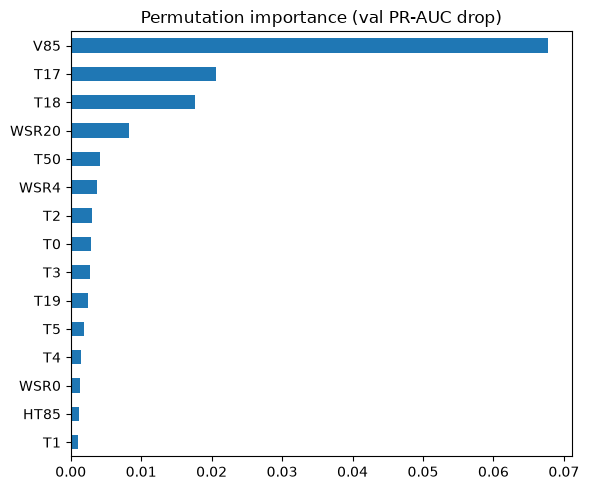

V85      0.0678
T17      0.0206
T18      0.0177
WSR20    0.0082
T50      0.0042
WSR4     0.0037
T2       0.0030
T0       0.0029
T3       0.0027
T19      0.0024
dtype: float64

In [9]:
perm = permutation_importance(model, X_val, y_val, scoring="average_precision", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=features).sort_values()
imp.tail(15).plot.barh(figsize=(6, 5)); plt.title("Permutation importance (val PR-AUC drop)"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(10).round(4)

### 8. Save chosen settings for the comparison notebook

In [10]:
json.dump({"params": best_params, "thr_f1": float(thr_f1), "thr_r70": float(thr_r70)},
          open(RESULTS / "random_forest_best.json", "w"), indent=2, default=str)

## Summary

**Tuning:** 18 settings, scored by 5-fold time-series CV PR-AUC on train + validation. Best: `max_depth=8, max_features="sqrt", min_samples_leaf=20` (300 trees, `class_weight="balanced_subsample"`). Most settings score within ~0.02 of each other, so the forest is not very sensitive to these choices.

**Results:**
| | ROC-AUC | PR-AUC | Random PR-AUC |
|---|---|---|---|
| Train | 0.971 | 0.749 | 0.076 |
| Validation | 0.834 | 0.317 | 0.051 |
| Test | 0.968 | 0.625 | 0.031 |
| 5-fold CV | 0.860 ± 0.035 | 0.366 ± 0.070 | ~0.07 |

At the best-F1 validation threshold (0.73): test precision 0.54, recall 0.64 (7 of 11 ozone days caught, 13 warnings).

**Important features:** V85 (north–south wind at 850 hPa) dominates, followed by late-afternoon temperatures (T17, T18).

**Caveats:** Large train/validation gap (PR-AUC 0.75 vs 0.32), so the forest still overfits. Validation was part of the tuning data, so validation metrics are slightly optimistic; the test set was not used for any choice.